In [78]:
import yfinance as yf
sp500 = yf.Ticker("^GSPC")
sp500 = sp500.history (period ="max")
sp500

,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
1927-12-30 00:00:00-05:00,17.660000,17.660000,17.660000,17.660000,0,0.0,0.0
1928-01-03 00:00:00-05:00,17.760000,17.760000,17.760000,17.760000,0,0.0,0.0
1928-01-04 00:00:00-05:00,17.719999,17.719999,17.719999,17.719999,0,0.0,0.0
1928-01-05 00:00:00-05:00,17.549999,17.549999,17.549999,17.549999,0,0.0,0.0
1928-01-06 00:00:00-05:00,17.660000,17.660000,17.660000,17.660000,0,0.0,0.0
...,...,...,...,...,...,...,...
2025-10-31 00:00:00-04:00,6879.169922,6879.169922,6814.259766,6840.200195,6398280000,0.0,0.0
2025-11-03 00:00:00-05:00,6882.319824,6882.319824,6820.620117,6851.970215,6065720000,0.0,0.0
2025-11-04 00:00:00-05:00,6788.520020,6820.209961,6766.709961,6771.549805,5739510000,0.0,0.0


In [40]:
sp500.index


DatetimeIndex(['1927-12-30 00:00:00-05:00', '1928-01-03 00:00:00-05:00',
               '1928-01-04 00:00:00-05:00', '1928-01-05 00:00:00-05:00',
               '1928-01-06 00:00:00-05:00', '1928-01-09 00:00:00-05:00',
               '1928-01-10 00:00:00-05:00', '1928-01-11 00:00:00-05:00',
               '1928-01-12 00:00:00-05:00', '1928-01-13 00:00:00-05:00',
               ...
               '2025-10-24 00:00:00-04:00', '2025-10-27 00:00:00-04:00',
               '2025-10-28 00:00:00-04:00', '2025-10-29 00:00:00-04:00',
               '2025-10-30 00:00:00-04:00', '2025-10-31 00:00:00-04:00',
               '2025-11-03 00:00:00-05:00', '2025-11-04 00:00:00-05:00',
               '2025-11-05 00:00:00-05:00', '2025-11-06 00:00:00-05:00'],
              dtype='datetime64[ns, America/New_York]', name='Date', length=24580, freq=None)

<Axes: xlabel='Date'>

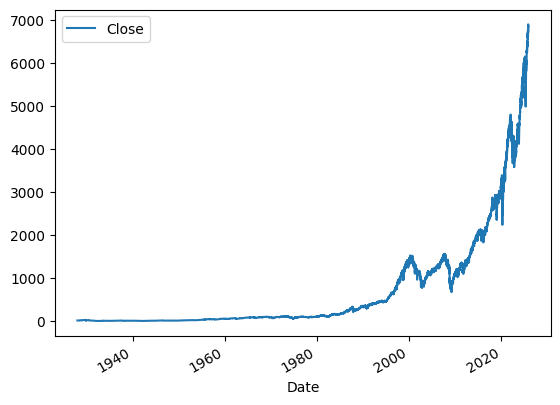

In [48]:
sp500.plot.line(y="Close", use_index=True)


In [80]:
del sp500["Stock Splits"]
del sp500["Dividends"]
sp500["Tomorrow"] = sp500["Close"].shift(-1)
sp500


,Open,High,Low,Close,Volume,Tomorrow
Date,,,,,,
1927-12-30 00:00:00-05:00,17.660000,17.660000,17.660000,17.660000,0,17.760000
1928-01-03 00:00:00-05:00,17.760000,17.760000,17.760000,17.760000,0,17.719999
1928-01-04 00:00:00-05:00,17.719999,17.719999,17.719999,17.719999,0,17.549999
1928-01-05 00:00:00-05:00,17.549999,17.549999,17.549999,17.549999,0,17.660000
1928-01-06 00:00:00-05:00,17.660000,17.660000,17.660000,17.660000,0,17.500000
...,...,...,...,...,...,...
2025-10-31 00:00:00-04:00,6879.169922,6879.169922,6814.259766,6840.200195,6398280000,6851.970215
2025-11-03 00:00:00-05:00,6882.319824,6882.319824,6820.620117,6851.970215,6065720000,6771.549805
2025-11-04 00:00:00-05:00,6788.520020,6820.209961,6766.709961,6771.549805,5739510000,6796.290039


In [89]:
sp500["Target"] = (sp500["Tomorrow"] > sp500["Close"]).astype(int)
sp500

,Open,High,Low,Close,Volume,Tomorrow,Target
Date,,,,,,,
1927-12-30 00:00:00-05:00,17.660000,17.660000,17.660000,17.660000,0,17.760000,1
1928-01-03 00:00:00-05:00,17.760000,17.760000,17.760000,17.760000,0,17.719999,0
1928-01-04 00:00:00-05:00,17.719999,17.719999,17.719999,17.719999,0,17.549999,0
1928-01-05 00:00:00-05:00,17.549999,17.549999,17.549999,17.549999,0,17.660000,1
1928-01-06 00:00:00-05:00,17.660000,17.660000,17.660000,17.660000,0,17.500000,0
...,...,...,...,...,...,...,...
2025-10-31 00:00:00-04:00,6879.169922,6879.169922,6814.259766,6840.200195,6398280000,6851.970215,1
2025-11-03 00:00:00-05:00,6882.319824,6882.319824,6820.620117,6851.970215,6065720000,6771.549805,0
2025-11-04 00:00:00-05:00,6788.520020,6820.209961,6766.709961,6771.549805,5739510000,6796.290039,1


In [90]:
sp500 = sp500.loc["1990-01-01":].copy()
sp500

,Open,High,Low,Close,Volume,Tomorrow,Target
Date,,,,,,,
1990-01-02 00:00:00-05:00,353.399994,359.690002,351.980011,359.690002,162070000,358.760010,0
1990-01-03 00:00:00-05:00,359.690002,360.589996,357.890015,358.760010,192330000,355.670013,0
1990-01-04 00:00:00-05:00,358.760010,358.760010,352.890015,355.670013,177000000,352.200012,0
1990-01-05 00:00:00-05:00,355.670013,355.670013,351.350006,352.200012,158530000,353.790009,1
1990-01-08 00:00:00-05:00,352.200012,354.239990,350.540009,353.790009,140110000,349.619995,0
...,...,...,...,...,...,...,...
2025-10-31 00:00:00-04:00,6879.169922,6879.169922,6814.259766,6840.200195,6398280000,6851.970215,1
2025-11-03 00:00:00-05:00,6882.319824,6882.319824,6820.620117,6851.970215,6065720000,6771.549805,0
2025-11-04 00:00:00-05:00,6788.520020,6820.209961,6766.709961,6771.549805,5739510000,6796.290039,1


In [94]:
from sklearn.ensemble import RandomForestClassifier
model = RandomForestClassifier(n_estimators=100,min_samples_split=100, random_state=1)
train = sp500.iloc[:-100]
test = sp500.iloc[-100:]

predictors =["Close", "Volume", "Open" , "Low" ]
model.fit(train[predictors], train["Target"])

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,100
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [100]:
from sklearn.metrics import precision_score
import pandas as pd
preds = model.predict(test[predictors])

preds = pd.Series(preds, index=test.index)
precision_score(test["Target"],preds)

0.5

<Axes: xlabel='Date'>

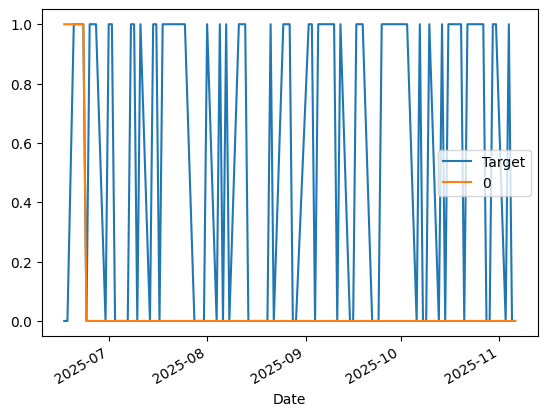

In [104]:
combined = pd.concat([test["Target"], preds], axis=1)
combined.plot()

In [128]:
def predict(train, test, predictors, model):
    model.fit(train[predictors], train["Target"])
    preds = model.predict(test[predictors])
    preds = pd.Series(preds, index=test.index, name="Predictions")
    combined = pd.concat([test["Target"], preds], axis=1) 
    return combined
     

In [129]:
def backtest(data, model, predictors, start=2500, step=250):
    all_predictions = []

    for i in range(start, data.shape[0], step):
        train = data.iloc[0:i].copy()
        test = data.iloc[i:(i+step)].copy()
        predictions = predict(train, test, predictors, model)
        all_predictions.append(predictions)
    return pd.concat(all_predictions)

In [138]:
predictions = backtest(sp500, model, predictors)

In [140]:
predictions["Predictions"].value_counts()

Predictions
0    3909
1    2621
Name: count, dtype: int64

In [143]:
precision_score(predictions["Target"], predictions["Predictions"])

0.5333842045020984

In [145]:
predictions["Target"].value_counts() /predictions.shape[0]

Target
1    0.537213
0    0.462787
Name: count, dtype: float64

In [154]:
horizons = [2,5,60,250,1000]
new_predictors = []

for horizon in horizons:
    rolling_averages = sp500.rolling(horizon).mean()

    ratio_column = f"Close_Ratio_{horizon}"
    sp500[ratio_column] = sp500["Close"] / rolling_averages["Close"]

    trend_column = f"Trend_{horizon}"
    sp500[trend_column] = sp500.shift(1).rolling(horizon).sum()["Target"]

    new_predictors += [ratio_column, trend_column]
    

    


In [156]:
sp500 = sp500.dropna()

In [157]:
sp500

,Open,High,Low,Close,Volume,Tomorrow,Target,Close_Ration_2,Close_Ratio_2,Trend_2,Close_Ratio_5,Trend_5,Close_Ratio_60,Trend_60,Close_Ratio_250,Trend_250,Close_Ratio_1000,Trend_1000
Date,,,,,,,,,,,,,,,,,,
1993-12-14 00:00:00-05:00,465.730011,466.119995,462.459991,463.059998,275050000,461.839996,0,0.997157,0.997157,1.0,0.996617,1.0,1.000283,32.0,1.028047,127.0,1.176082,512.0
1993-12-15 00:00:00-05:00,463.059998,463.690002,461.839996,461.839996,331770000,463.339996,1,0.998681,0.998681,0.0,0.995899,1.0,0.997329,32.0,1.025151,126.0,1.172676,512.0
1993-12-16 00:00:00-05:00,461.859985,463.980011,461.859985,463.339996,284620000,466.380005,1,1.001621,1.001621,1.0,0.999495,2.0,1.000311,32.0,1.028274,127.0,1.176163,513.0
1993-12-17 00:00:00-05:00,463.339996,466.380005,463.339996,466.380005,363750000,465.850006,0,1.003270,1.003270,2.0,1.004991,3.0,1.006561,32.0,1.034781,128.0,1.183537,514.0
1993-12-20 00:00:00-05:00,466.380005,466.899994,465.529999,465.850006,255900000,465.299988,0,0.999431,0.999431,1.0,1.003784,2.0,1.005120,32.0,1.033359,128.0,1.181856,513.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-10-30 00:00:00-04:00,6860.500000,6880.750000,6820.689941,6822.339844,6052700000,6840.200195,1,0.995023,0.995023,0.0,0.995361,3.0,1.034417,35.0,1.122786,144.0,1.387110,528.0
2025-10-31 00:00:00-04:00,6879.169922,6879.169922,6814.259766,6840.200195,6398280000,6851.970215,1,1.001307,1.001307,1.0,0.996556,3.0,1.035816,36.0,1.124885,145.0,1.390136,528.0
2025-11-03 00:00:00-05:00,6882.319824,6882.319824,6820.620117,6851.970215,6065720000,6771.549805,0,1.000860,1.000860,2.0,0.998946,3.0,1.036388,36.0,1.125988,145.0,1.391920,528.0


In [158]:
model = RandomForestClassifier(n_estimators=200, min_samples_split=50, random_state=1)

In [160]:
def predict(train, test, predictors, model):
    model.fit(train[predictors], train["Target"])
    preds = model.predict_proba(test[predictors])[:,1]
    preds[preds >= .6] = 1
    preds[preds < .6] = 0
    preds = pd.Series(preds, index=test.index, name="Predictions")
    combined = pd.concat([test["Target"], preds], axis=1) 
    return combined

In [161]:
predictions = backtest(sp500, model, new_predictors)

In [162]:
predictions["Predictions"].value_counts()

Predictions
0.0    4657
1.0     872
Name: count, dtype: int64

In [164]:
precision_score(predictions["Target"], predictions["Predictions"])

0.5722477064220184